In [31]:
#run beginning of the script
import numpy as np

# Compatibility aliases required by pySCENIC 0.12.1.
legacy_numpy_aliases = {
    "bool": bool,
    "int": int,
    "float": float,
    "complex": complex,
    "object": object,
    "str": str,
}

for name, value in legacy_numpy_aliases.items():
    if name not in np.__dict__:
        setattr(np, name, value)

In [32]:
import os
import pandas as pd
import numpy as np
import scanpy as sc
import loompy as lp

In [33]:
from pyscenic.plotting import plot_binarization
from pyscenic.export import add_scenic_metadata

In [34]:
import pyscenic
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
rss_parent_path = "/home/jiafzhou/GRN_org/results"
drug_list = ["dmso", "m114", "m118", "m124", "m131", "m135"]

In [35]:
from pathlib import Path

from pyscenic.cli.utils import load_signatures
from pyscenic.export import export_regulons


In [ ]:
drug = "m114"
cell_type = "NE_2"

result_dir = Path(f"/home/jiafzhou/GRN_org/results/{drug}")

rss = pd.read_csv(
    result_dir / "rss_cellType.csv",
    index_col=0,
)

#get top 5 regulons for NE_2 cell type
top_regulon_names = (
    rss.loc[cell_type]
    .nlargest(5)
    .index
    .tolist()
)

regulons = load_signatures(
    str(result_dir / "regulons.csv")
)

selected_regulons = [
    regulon
    for regulon in regulons
    if regulon.name in top_regulon_names
]

Create regulons from a dataframe of enriched features.
Additional columns saved: []


In [10]:
selected_regulons

[Regulon(name='ETS1(+)', gene2weight=frozendict.frozendict({'PLP1': 3.512339242714441, 'RBMS3': 3.462809148090324, 'ZBTB7C': 3.9865147713884905, 'PDE4D': 8.228562317734216, 'BNC2': 10.300342756659653, 'MEF2C': 4.698138679606461, 'DISC1': 8.183051250489951, 'PRKCE': 3.249096193437402, 'COL1A2': 17.16770044240466, 'PTPRE': 8.816641315078531, 'MAML2': 13.23521985671672, 'RUNX2': 48.82600746205963, 'CCDC3': 7.844954749950734, 'STARD13': 41.99072922198693, 'ETS1': 1.0, 'RHOJ': 15.045944355532976, 'BACE2': 19.84256207812884, 'EPHA6': 6.87935573439641, 'HMCN1': 7.749297641290257}), gene2occurrence=frozendict.frozendict({}), transcription_factor='ETS1', context=frozenset({'activating', 'dbcorrdb__SUPT20H__ENCSR000ECQ_1__m5.png'}), score=3.132462623043878, nes=0.0, orthologous_identity=0.0, similarity_qvalue=0.0, annotation=''),
 Regulon(name='JUN(+)', gene2weight=frozendict.frozendict({'HSPA8': 4.69342899902681, 'HSPD1': 3.821925602186461, 'HSP90AB1': 3.4029013849649488, 'DNAJA1': 4.7161551037

use regulon.csv to build network

In [13]:
import networkx as nx


def export_regulons_graphml(
    regulons,
    output_file,
    max_targets_per_regulon=50,
):
    graph = nx.DiGraph()

    for regulon in regulons:
        tf = str(regulon.transcription_factor)
        context = sorted(str(value) for value in regulon.context)
        context_text = "; ".join(context)

        activating = "activating" in regulon.context
        interaction = "activating" if activating else "inhibiting"
        target_group = (
            "activated_target" if activating
            else "inhibited_target"
        )

        graph.add_node(
            tf,
            group="transcription_factor",
        )

        targets = sorted(
            regulon.gene2weight.items(),
            key=lambda item: float(item[1]),
            reverse=True,
        )

        if max_targets_per_regulon is not None:
            targets = targets[:max_targets_per_regulon]

        for target, weight in targets:
            target = str(target)

            if target not in graph:
                graph.add_node(
                    target,
                    group=target_group,
                )

            graph.add_edge(
                tf,
                target,
                weight=float(weight),
                interaction=interaction,
                regulon=str(regulon.name),
                context=context_text,
            )

    output_file = Path(output_file)
    output_file.parent.mkdir(parents=True, exist_ok=True)

    nx.write_graphml(graph, output_file)

    print("Created:", output_file)
    print("Regulons:", len(regulons))
    print("Nodes:", graph.number_of_nodes())
    print("Edges:", graph.number_of_edges())

    return graph

In [14]:
output_graphml = (
    result_dir
    / f"{cell_type}_top5_regulons.graphml"
)

graph = export_regulons_graphml(
    selected_regulons,
    output_graphml,
    max_targets_per_regulon=50,
)

Created: /home/jiafzhou/GRN_org/results/m114/NE_2_top5_regulons.graphml
Regulons: 5
Nodes: 136
Edges: 148


In [ ]:
graphml_file = (
    "/home/jiafzhou/GRN_org/results/"
    "m114/NE_2_top5_regulons.graphml"
)

graph = nx.read_graphml(graphml_file)

print("Nodes:", graph.number_of_nodes())
print("Edges:", graph.number_of_edges())
print("First nodes:", list(graph.nodes(data=True))[:5])
print("First edges:", list(graph.edges(data=True))[:5])

Nodes: 136
Edges: 148
First nodes: [('ETS1', {'group': 'transcription_factor'}), ('RUNX2', {'group': 'activated_target'}), ('STARD13', {'group': 'activated_target'}), ('BACE2', {'group': 'activated_target'}), ('COL1A2', {'group': 'activated_target'})]
First edges: [('ETS1', 'RUNX2', {'weight': 48.82600746205963, 'interaction': 'activating', 'regulon': 'ETS1(+)', 'context': 'activating; dbcorrdb__SUPT20H__ENCSR000ECQ_1__m5.png'}), ('ETS1', 'STARD13', {'weight': 41.99072922198693, 'interaction': 'activating', 'regulon': 'ETS1(+)', 'context': 'activating; dbcorrdb__SUPT20H__ENCSR000ECQ_1__m5.png'}), ('ETS1', 'BACE2', {'weight': 19.84256207812884, 'interaction': 'activating', 'regulon': 'ETS1(+)', 'context': 'activating; dbcorrdb__SUPT20H__ENCSR000ECQ_1__m5.png'}), ('ETS1', 'COL1A2', {'weight': 17.16770044240466, 'interaction': 'activating', 'regulon': 'ETS1(+)', 'context': 'activating; dbcorrdb__SUPT20H__ENCSR000ECQ_1__m5.png'}), ('ETS1', 'RHOJ', {'weight': 15.045944355532976, 'interactio

TF nodes: ['ETS1', 'JUN', 'MAFF', 'RXRG', 'TPI1']
Target nodes: 131


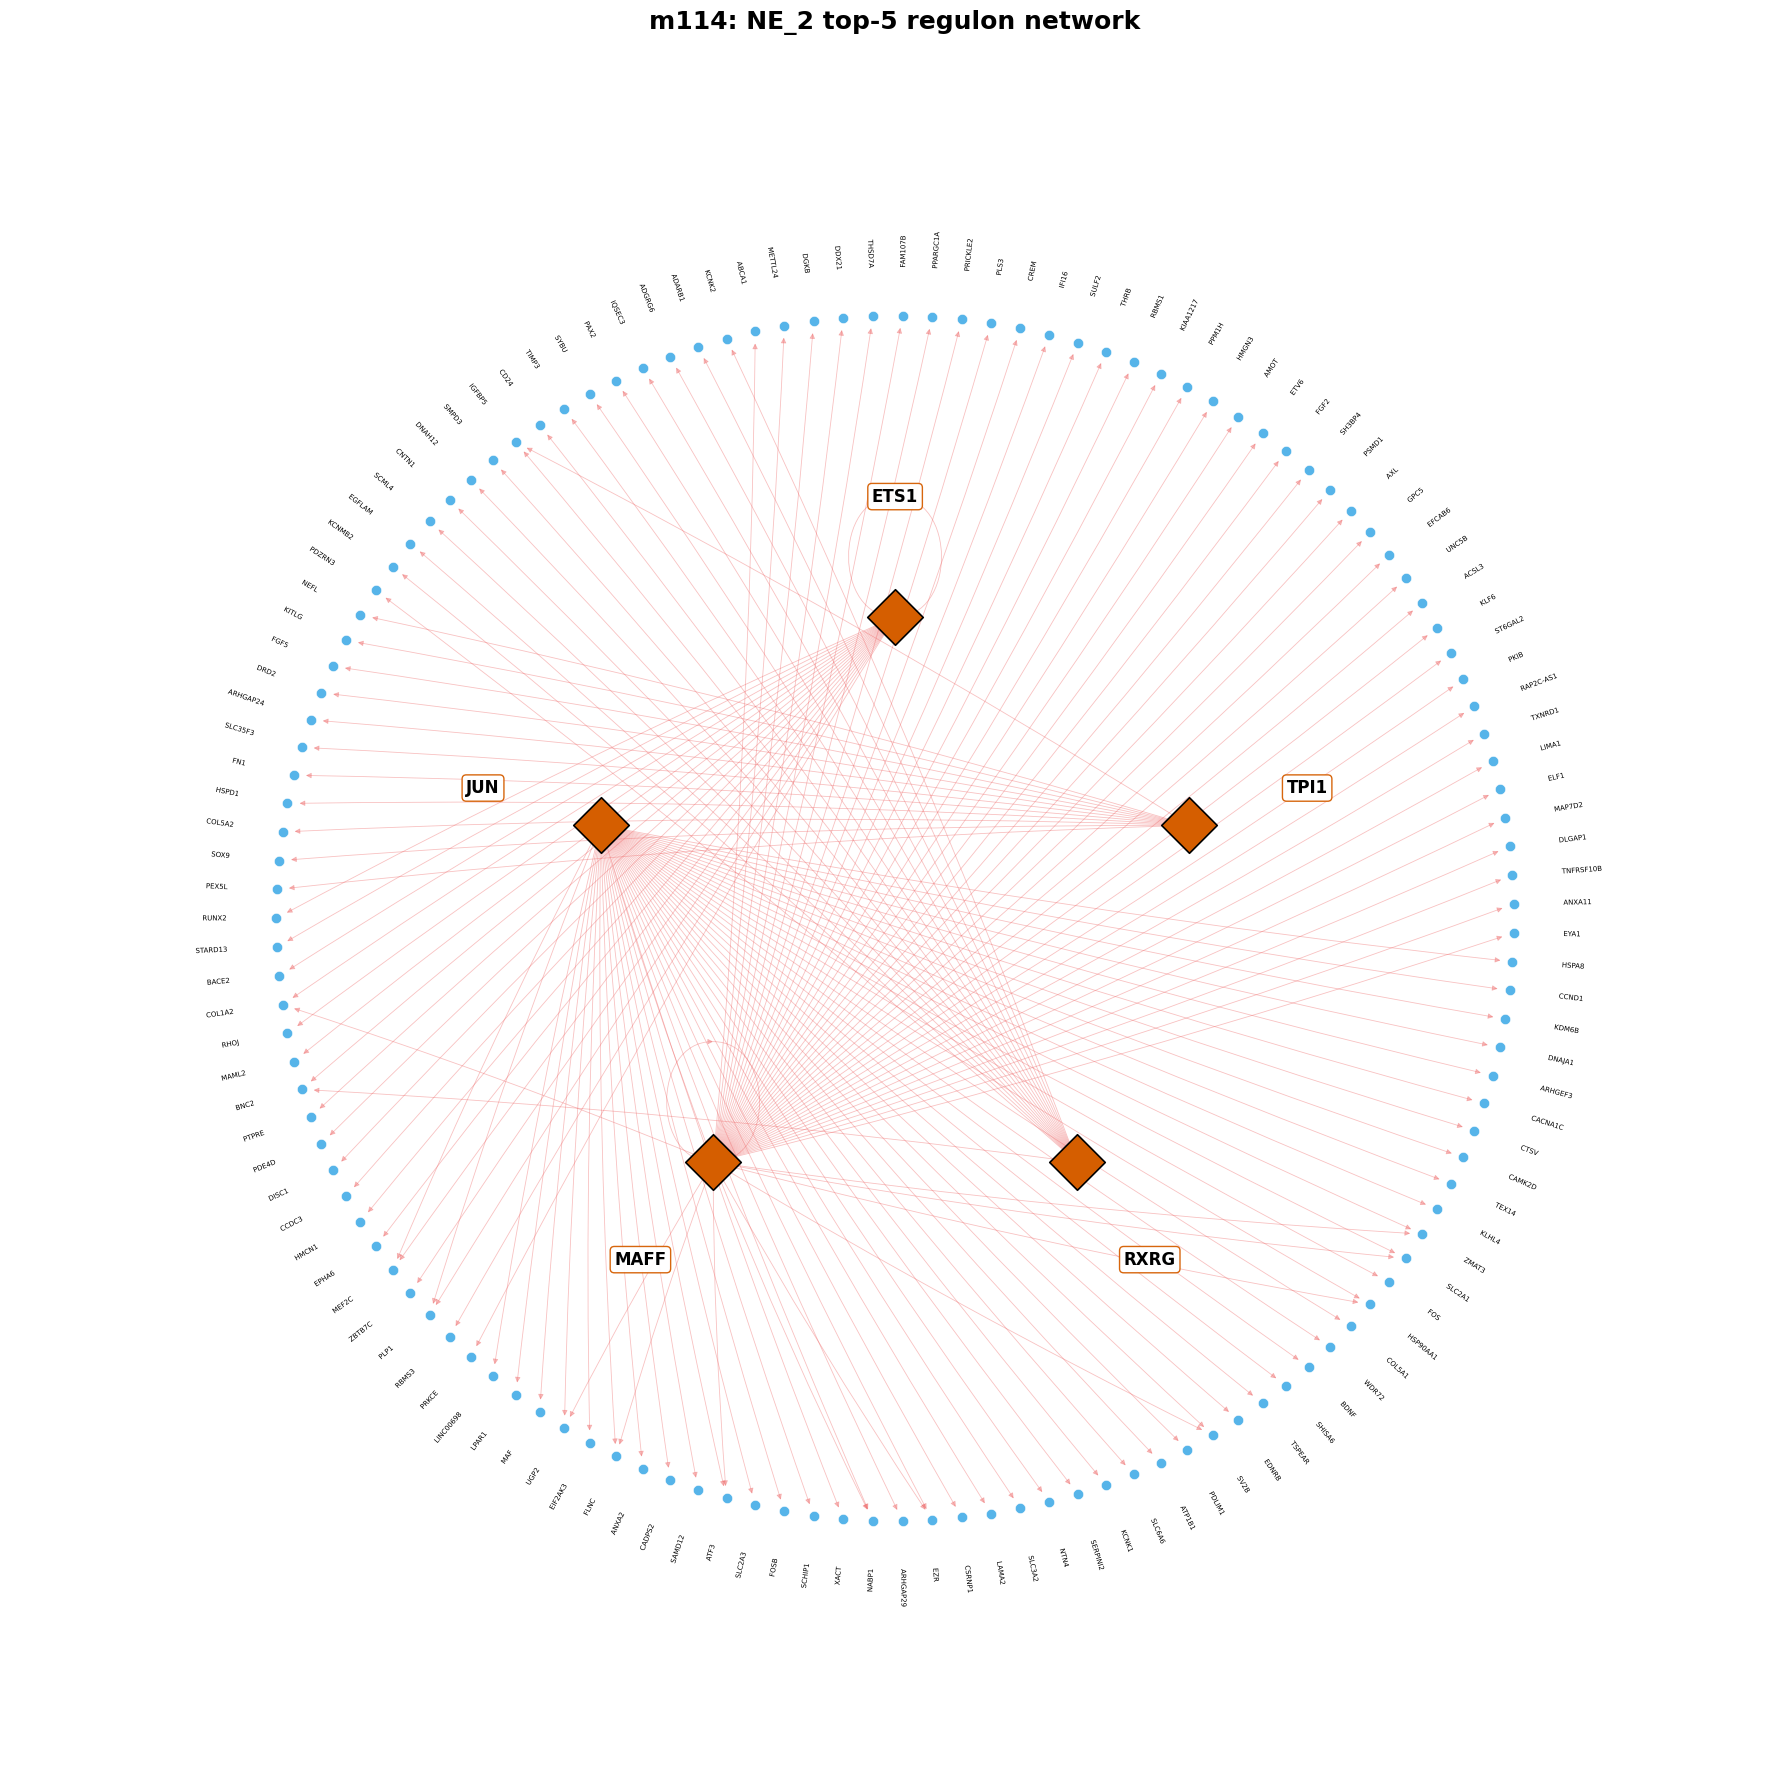

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects



tf_nodes = [
    node
    for node, attributes in graph.nodes(data=True)
    if attributes.get("group") == "transcription_factor"
]

target_nodes = [
    node
    for node in graph.nodes
    if node not in tf_nodes
]

print("TF nodes:", tf_nodes)
print("Target nodes:", len(target_nodes))

# TF inside，target genes outside。
position = nx.shell_layout(
    graph,
    nlist=[tf_nodes, target_nodes],
    scale=5,
)

fig, ax = plt.subplots(figsize=(18, 18))

# Edges

edge_colors = []

for source, target, attributes in graph.edges(data=True):
    interaction = attributes.get("interaction", "activating")

    if interaction == "inhibiting":
        edge_colors.append("#0072B2")
    else:
        edge_colors.append("#EE6565")

nx.draw_networkx_edges(
    graph,
    position,
    ax=ax,
    edge_color=edge_colors,
    width=0.6,
    alpha=0.40,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=8,
    connectionstyle="arc3,rad=0.02",
)


# Draw target genes.
nx.draw_networkx_nodes(
    graph,
    position,
    nodelist=target_nodes,
    ax=ax,
    node_size=55,
    node_color="#56B4E9",
    edgecolors="white",
    linewidths=0.4,
)


# Draw TFs.
nx.draw_networkx_nodes(
    graph,
    position,
    nodelist=tf_nodes,
    ax=ax,
    node_size=800,
    node_color="#D55E00",
    edgecolors="black",
    linewidths=1.2,
    node_shape="D",
)

# 7. Add TF labels

tf_label_position = {}
tf_label_offset = 1.0

for node in tf_nodes:
    x, y = position[node]
    radius = np.hypot(x, y)

    if radius == 0:
        tf_label_position[node] = (
            x,
            y + tf_label_offset,
        )
    else:
        tf_label_position[node] = (
            x + tf_label_offset * x / radius,
            y + tf_label_offset * y / radius,
        )

nx.draw_networkx_labels(
    graph,
    tf_label_position,
    labels={
        node: str(node)
        for node in tf_nodes
    },
    ax=ax,
    font_size=12,
    font_weight="bold",
    font_color="black",
    bbox={
        "boxstyle": "round,pad=0.25",
        "facecolor": "white",
        "edgecolor": "#D55E00",
        "alpha": 0.95,
    },
)

# 8. Add outer target-gene labels
target_label_offset = 0.40

for node in target_nodes:
    x, y = position[node]
    radius = np.hypot(x, y)

    if radius == 0:
        continue

    # Move the label outward from the target node.
    label_x = (
        x + target_label_offset * x / radius
    )
    label_y = (
        y + target_label_offset * y / radius
    )

    # Calculate the radial angle of the label.
    angle = np.degrees(np.arctan2(y, x))
    horizontal_alignment = "left"

    # Flip labels on the left side so they remain readable.
    if angle > 90 or angle < -90:
        angle += 180
        horizontal_alignment = "right"

    text = ax.text(
        label_x,
        label_y,
        str(node),
        fontsize=5,
        fontweight="normal",
        color="black",
        rotation=angle,
        rotation_mode="anchor",
        horizontalalignment=horizontal_alignment,
        verticalalignment="center",
        clip_on=False,
        zorder=10,
    )

    # White outline makes text readable over edges.
    text.set_path_effects([
        path_effects.withStroke(
            linewidth=1.5,
            foreground="white",
        )
    ])

ax.set_title(
    f"{drug}: {cell_type} top-5 regulon network",
    fontsize=18,
    fontweight="bold",
    pad=20,
)

ax.set_axis_off()
ax.margins(0.15)

plt.tight_layout()
plt.savefig(
    result_dir / f"{cell_type}_top5_regulons_network.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [24]:
for regulon in selected_regulons:
    print(
        regulon.name,
        regulon.context,
    )

ETS1(+) frozenset({'activating', 'dbcorrdb__SUPT20H__ENCSR000ECQ_1__m5.png'})
JUN(+) frozenset({'activating', 'hocomoco__CREB5_HUMAN.H11MO.0.D.png'})
MAFF(+) frozenset({'activating', 'dbcorrdb__FOS__ENCSR000DOO_1__m1.png'})
RXRG(+) frozenset({'activating', 'tfdimers__MD00368.png'})
TPI1(+) frozenset({'activating', 'hdpi__TPI1.png'})


heatmap cell type X regulon heatmap

In [6]:
import loompy

In [6]:
drug_all = pd.read_csv("/home/jiafzhou/GRN_org/config/included_drugs.txt", header=None)

In [7]:
DRUGS = drug_all[0].tolist()

In [10]:
base_result_dir = Path(f"/home/jiafzhou/GRN_org/results")

In [11]:
DRUGS_exist = []

for i in range(len(DRUGS)):
    auc_file = (
        base_result_dir
        / DRUGS[i]
        / "auc_mtx_dmso_ref.csv"
    )

    loom_file = (base_result_dir / DRUGS[i] / "input.loom")

    if not auc_file.is_file():
        print(f"Skip {DRUGS[i]}: AUC file missing")
        continue

    if not loom_file.is_file():
        print(f"Skip {DRUGS[i]}: Loom file missing")
        continue

    DRUGS_exist.append(DRUGS[i])

Skip m128: AUC file missing
Skip m125: AUC file missing
Skip m129: AUC file missing
Skip m140: AUC file missing
Skip short-117: AUC file missing
Skip short-113: AUC file missing


In [12]:
#import cell type annotation from loom file

mean_auc_tables = {}

for drug in DRUGS_exist:
    auc_file = (
        base_result_dir
        / drug
        / "auc_mtx_dmso_ref.csv"
    )

    auc = pd.read_csv(
        base_result_dir / drug / "auc_mtx_dmso_ref.csv",
        index_col=0,
        )
        
    auc.index = auc.index.astype(str)
    auc.columns = auc.columns.astype(str)

    with loompy.connect(
        str(base_result_dir / drug / "input.loom"),
        mode="r",
        validate=False,
    ) as ds:
        print(drug, list(ds.ca.keys()))

        cells = pd.Index(
            ds.ca["CellID"].astype(str)
        )

        # Change this key if your Loom uses a different name
        cell_types = pd.Series(
            ds.ca["CellType"].astype(str),
            index=cells,
            name="cell_type",
        )

    common_cells = auc.index.intersection(cell_types.index)

    mean_auc = (
        auc.loc[common_cells]
        .groupby(cell_types.loc[common_cells])
        .mean()
    )

    mean_auc.index.name = "cell_type"
    mean_auc_tables[drug] = mean_auc

    print(
        drug,
        "cells:", len(common_cells),
        "mean AUC shape:", mean_auc.shape,
    )

m124 ['CellID', 'CellType', 'Drug', 'Timepoint']
m124 cells: 25021 mean AUC shape: (11, 60)
m127 ['CellID', 'CellType', 'Drug', 'Timepoint']
m127 cells: 24783 mean AUC shape: (12, 60)
m121 ['CellID', 'CellType', 'Drug', 'Timepoint']
m121 cells: 24350 mean AUC shape: (12, 60)
m122 ['CellID', 'CellType', 'Drug', 'Timepoint']
m122 cells: 23505 mean AUC shape: (12, 60)
m126 ['CellID', 'CellType', 'Drug', 'Timepoint']
m126 cells: 21230 mean AUC shape: (12, 60)
m120 ['CellID', 'CellType', 'Drug', 'Timepoint']
m120 cells: 21389 mean AUC shape: (11, 60)
m138 ['CellID', 'CellType', 'Drug', 'Timepoint']
m138 cells: 22308 mean AUC shape: (12, 60)
m130 ['CellID', 'CellType', 'Drug', 'Timepoint']
m130 cells: 21128 mean AUC shape: (12, 60)
m114 ['CellID', 'CellType', 'Drug', 'Timepoint']
m114 cells: 20779 mean AUC shape: (12, 60)
m108 ['CellID', 'CellType', 'Drug', 'Timepoint']
m108 cells: 20336 mean AUC shape: (12, 60)
m119 ['CellID', 'CellType', 'Drug', 'Timepoint']
m119 cells: 19213 mean AUC shap

In [13]:
mean_auc_tables

{'m124':                ATF3(+)    CRX(+)   DLX1(+)   DLX2(+)   DLX5(+)   DLX6(+)  \
 cell_type                                                                  
 ASC           0.015526  0.022957  0.068192  0.081959  0.049091  0.034886   
 DTel_Neuron   0.018641  0.021977  0.125924  0.163769  0.135111  0.077544   
 Di_RG         0.022879  0.031296  0.047281  0.058277  0.040925  0.027647   
 Early_Neuron  0.023866  0.032871  0.124265  0.161003  0.144015  0.075223   
 Glioblast     0.015934  0.023751  0.060833  0.076215  0.053663  0.030285   
 NC            0.015680  0.020631  0.101621  0.130780  0.094746  0.057899   
 NE_1          0.032830  0.027745  0.056743  0.072172  0.049462  0.035269   
 NonTel_NE     0.024639  0.025663  0.075457  0.097249  0.066109  0.044137   
 RG            0.018533  0.022481  0.070768  0.086688  0.053961  0.039396   
 Unknown       0.017581  0.023034  0.097790  0.123894  0.090866  0.057345   
 VTel_Neuron   0.019810  0.022246  0.185305  0.232879  0.201145  0.1

In [14]:
common_regulons = set.intersection(
    *(set(df.columns) for df in mean_auc_tables.values())
)
common_regulons = sorted(common_regulons)
len(common_regulons)

60

In [15]:
common_celltypes = set.intersection(
    *(set(df.index) for df in mean_auc_tables.values())
)

In [16]:
celltype_order = [
    cell_type
    for cell_type in mean_auc_tables["dmso"].index
    if cell_type in common_celltypes
]

mean_auc_combined = pd.concat(
    {
        condition: mean_auc_tables[condition].loc[
            celltype_order,
            common_regulons,
        ]
        for condition in DRUGS_exist
    },
    names=["condition", "cell_type"],
)

print(mean_auc_combined.shape)

(252, 60)


In [17]:
common_regulons

['ATF3(+)',
 'CRX(+)',
 'DLX1(+)',
 'DLX2(+)',
 'DLX5(+)',
 'DLX6(+)',
 'DMBX1(+)',
 'EBF1(+)',
 'EGR1(+)',
 'EOMES(+)',
 'ETS1(+)',
 'FOSL2(+)',
 'GBX1(+)',
 'HDAC2(+)',
 'HMGA2(+)',
 'HOXB3(+)',
 'IRF6(+)',
 'JUN(+)',
 'JUNB(+)',
 'LHX2(+)',
 'LHX6(+)',
 'LMX1A(+)',
 'LMX1B(+)',
 'MAFF(+)',
 'MEF2C(+)',
 'MEIS1(+)',
 'MEIS2(+)',
 'MSX2(+)',
 'MYEF2(+)',
 'NEUROD1(+)',
 'NFIB(+)',
 'ONECUT1(+)',
 'ONECUT2(+)',
 'OTP(+)',
 'OTX2(+)',
 'PAX5(+)',
 'PBX1(+)',
 'POU2F2(+)',
 'POU3F1(+)',
 'POU3F3(+)',
 'POU4F1(+)',
 'POU5F1(+)',
 'PRDM1(+)',
 'RBMS1(+)',
 'RORA(+)',
 'SALL1(+)',
 'SIX6(+)',
 'SMAD3(+)',
 'SOX10(+)',
 'SOX11(+)',
 'SOX2(+)',
 'SOX4(+)',
 'SOX5(+)',
 'TCF7L2(+)',
 'TEAD1(+)',
 'TFAP2B(+)',
 'TPI1(+)',
 'UNCX(+)',
 'VSX2(+)',
 'XBP1(+)']

In [18]:
mean_auc_combined

ATF3(+)    CRX(+)   DLX1(+)   DLX2(+)   DLX5(+)  \
condition cell_type                                                        
m124      ASC           0.015526  0.022957  0.068192  0.081959  0.049091   
          Di_RG         0.022879  0.031296  0.047281  0.058277  0.040925   
          Early_Neuron  0.023866  0.032871  0.124265  0.161003  0.144015   
          Glioblast     0.015934  0.023751  0.060833  0.076215  0.053663   
          NC            0.015680  0.020631  0.101621  0.130780  0.094746   
...                          ...       ...       ...       ...       ...   
m109      NC            0.027750  0.023855  0.035669  0.044966  0.039197   
          NE_1          0.039800  0.027275  0.029984  0.034091  0.024661   
          RG            0.019360  0.026391  0.051869  0.061802  0.036599   
          Unknown       0.024759  0.024958  0.046569  0.054747  0.038554   
          VTel_Neuron   0.026838  0.013768  0.148259  0.175536  0.167296   

                         DLX6(+)  DMBX1(+)   EBF1(+)   EGR1(+)  EOMES(+)  ...  \
condition cell_type                                                       ...   
m124      ASC           0.034886  0.014505  0.030040  0.017405  0.028457  ...   
          Di_RG         0.027647  0.007855  0.022133  0.033289  0.026847  ...   
          Early_Neuron  0.075223  0.005969  0.211510  0.014980  0.113824  ...   
          Glioblast     0.030285  0.022706  0.033686  0.016818  0.042121  ...   
          NC            0.057899  0.006421  0.082379  0.015258  0.047562  ...   
...                          ...       ...       ...       ...       ...  ...   
m109      NC            0.026359  0.025616  0.065374  0.032552  0.032522  ...   
          NE_1          0.024792  0.026474  0.028422  0.027016  0.025103  ...   
          RG            0.040553  0.015590  0.021182  0.018835  0.026194  ...   
          Unknown       0.035587  0.022578  0.027990  0.027421  0.034743  ...   
          VTel_Neuron   0.127560  0.000466  0.047952  0.018478  0.064108  ...   

                         SOX2(+)   SOX4(+)   SOX5(+)  TCF7L2(+)  TEAD1(+)  \
condition cell_type                                                         
m124      ASC           0.052792  0.051795  0.475348   0.097504  0.231481   
          Di_RG         0.052952  0.049036  0.385237   0.101548  0.247914   
          Early_Neuron  0.033279  0.096452  0.358169   0.023056  0.145671   
          Glioblast     0.052553  0.052603  0.494078   0.143905  0.246575   
          NC            0.051592  0.068966  0.461786   0.088749  0.238870   
...                          ...       ...       ...        ...       ...   
m109      NC            0.039375  0.043815  0.308308   0.128673  0.228886   
          NE_1          0.055461  0.043969  0.181195   0.122306  0.173392   
          RG            0.046987  0.044742  0.419298   0.145061  0.196185   
          Unknown       0.045629  0.045584  0.369147   0.151514  0.211233   
          VTel_Neuron   0.041308  0.082228  0.330403   0.098046  0.143991   

                        TFAP2B(+)   TPI1(+)   UNCX(+)   VSX2(+)   XBP1(+)  
condition cell_type                                                        
m124      ASC            0.052376  0.053593  0.024693  0.078242  0.036183  
          Di_RG          0.028057  0.082957  0.021670  0.269646  0.042431  
          Early_Neuron   0.063834  0.053780  0.111642  0.064931  0.021626  
          Glioblast      0.054152  0.059087  0.030000  0.086052  0.028239  
          NC             0.058495  0.064294  0.038069  0.105181  0.023653  
...                           ...       ...       ...       ...       ...  
m109      NC             0.123248  0.042175  0.038018  0.089145  0.027060  
          NE_1           0.036817  0.084350  0.016971  0.083375  0.039235  
          RG             0.041639  0.049400  0.022370  0.086753  0.032420  
          Unknown        0.054743  0.049571  0.027135  0.138478  0.035221  
          VTel_Neuron    0.041533  0.048158  0.053503  0.075507  0.0

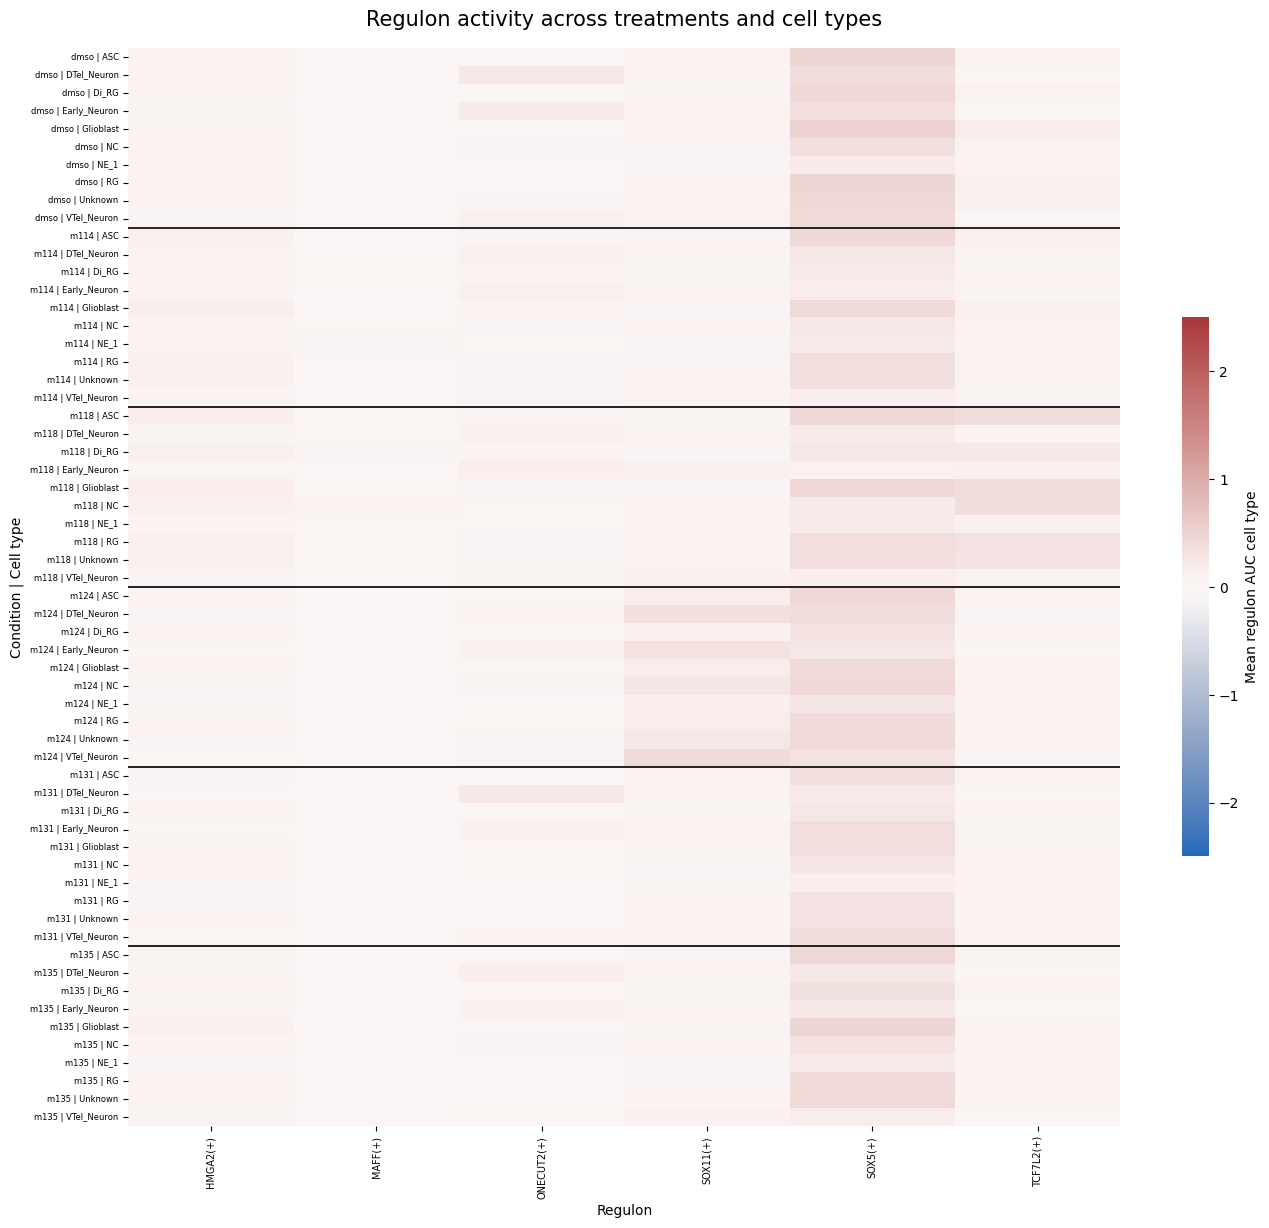

In [64]:
figure_dir = Path("/home/jiafzhou/GRN_org/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

n_rows, n_regulons = mean_auc_combined.shape

fig_width = max(16, n_regulons * 0.30)
fig_height = max(14, n_rows * 0.20)

fig, ax = plt.subplots(
    figsize=(fig_width, fig_height)
)

sns.heatmap(
    mean_auc_combined,
    ax=ax,
    cmap="vlag",
    center=0,
    vmin=-2.5,
    vmax=2.5,
    xticklabels=True,
    yticklabels=[
        f"{condition} | {cell_type}"
        for condition, cell_type in mean_auc_combined.index
    ],
    cbar_kws={
        "label": "Mean regulon AUC cell type",
        "shrink": 0.5,
    },
)

# Add horizontal lines between conditions
condition_sizes = (
    mean_auc_combined
    .groupby(level="condition", sort=False)
    .size()
)

for boundary in condition_sizes.cumsum().iloc[:-1]:
    ax.axhline(
        boundary,
        color="black",
        linewidth=1.2,
    )

ax.set_title(
    "Regulon activity across treatments and cell types",
    fontsize=15,
    pad=16,
)

ax.set_xlabel("Regulon")
ax.set_ylabel("Condition | Cell type")

ax.tick_params(
    axis="x",
    labelrotation=90,
    labelsize=7,
)

ax.tick_params(
    axis="y",
    labelrotation=0,
    labelsize=6,
)

plt.savefig(
    figure_dir / "all_regulons_AUC_heatmap.pdf",
    bbox_inches="tight",
)

plt.savefig(
    figure_dir / "all_regulons_AUC_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [131]:
dmso_mean_auc = mean_auc_combined.xs(
    "dmso",
    level="condition",
)

delta_mean_auc_tables = {}

for drug in DRUGS_exist:
    if drug == "dmso":
        continue

    drug_mean_auc = mean_auc_combined.xs(
        drug,
        level="condition",
    )

    delta_mean_auc_tables[drug] = (
        drug_mean_auc
        - dmso_mean_auc
    )

delta_mean_auc = pd.concat(
    delta_mean_auc_tables,
    names=["condition", "cell_type"],
)

delta_mean_auc

ATF3(+)    CRX(+)   DLX1(+)   DLX2(+)   DLX5(+)  \
condition cell_type                                                        
m124      ASC          -0.005440 -0.006928  0.014994  0.013601  0.002639   
          Di_RG         0.000983 -0.002515 -0.001950 -0.003948 -0.000132   
          Early_Neuron  0.001421 -0.002000  0.007610  0.010142  0.012926   
          Glioblast    -0.001680 -0.001867  0.006933  0.010499  0.006066   
          NC           -0.013329 -0.005499  0.052527  0.069571  0.044116   
...                          ...       ...       ...       ...       ...   
m109      NC           -0.001259 -0.002275 -0.013424 -0.016242 -0.011433   
          NE_1         -0.001316 -0.000863 -0.007707 -0.015325 -0.012302   
          RG           -0.001617 -0.002130 -0.014036 -0.018101 -0.016069   
          Unknown       0.002301 -0.001259 -0.029565 -0.040905 -0.031777   
          VTel_Neuron   0.002930 -0.012136 -0.053720 -0.066055 -0.042444   

                         DLX6(+)  DMBX1(+)   EBF1(+)   EGR1(+)  EOMES(+)  ...  \
condition cell_type                                                       ...   
m124      ASC           0.002742 -0.010530 -0.000646 -0.003542 -0.004681  ...   
          Di_RG        -0.001337 -0.002343 -0.001973  0.003979 -0.006678  ...   
          Early_Neuron  0.021464 -0.002017  0.001353  0.000336 -0.060936  ...   
          Glioblast     0.003638 -0.002147  0.000620  0.001397 -0.004169  ...   
          NC            0.027909 -0.021484 -0.016486 -0.012417  0.008724  ...   
...                          ...       ...       ...       ...       ...  ...   
m109      NC           -0.003631 -0.002289 -0.033490  0.004877 -0.006316  ...   
          NE_1         -0.000872  0.001558  0.012090  0.000561 -0.002238  ...   
          RG           -0.005064 -0.000072 -0.004547 -0.001247 -0.009922  ...   
          Unknown      -0.012584 -0.000735 -0.018025  0.007648 -0.014000  ...   
          VTel_Neuron  -0.029627 -0.009023 -0.043616  0.003166 -0.026297  ...   

                         SOX2(+)   SOX4(+)   SOX5(+)  TCF7L2(+)  TEAD1(+)  \
condition cell_type                                                         
m124      ASC          -0.005512  0.001577 -0.008111  -0.011296  0.000931   
          Di_RG         0.000028 -0.000203 -0.045430  -0.003601  0.001795   
          Early_Neuron -0.001129  0.000756 -0.004937  -0.006796  0.006179   
          Glioblast    -0.002962  0.000701 -0.017140  -0.028917  0.027222   
          NC           -0.003778  0.015740  0.121104  -0.022722  0.022391   
...                          ...       ...       ...        ...       ...   
m109      NC           -0.015995 -0.009410 -0.032374   0.017202  0.012407   
          NE_1         -0.007280 -0.005162 -0.043036   0.016994 -0.030100   
          RG           -0.014797 -0.008834 -0.050518   0.025608  0.015754   
          Unknown      -0.011164 -0.014561 -0.085149   0.022836 -0.010348   
          VTel_Neuron  -0.003956 -0.017938 -0.082870   0.061988  0.000651   

                        TFAP2B(+)   TPI1(+)   UNCX(+)   VSX2(+)   XBP1(+)  
condition cell_type                                                        
m124      ASC           -0.004455 -0.006564 -0.001042 -0.034133  0.004223  
          Di_RG         -0.001402  0.001344 -0.001515 -0.037645  0.004976  
          Early_Neuron  -0.003155 -0.005422 -0.027604 -0.027258 -0.022157  
          Glioblast      0.009706 -0.001638  0.002214 -0.007464 -0.001368  
          NC            -0.068081 -0.011735  0.012161 -0.003854 -0.008438  
...                           ...       ...       ...       ...       ...  
m109      NC            -0.003327 -0.033854  0.012109 -0.019890 -0.005032  
          NE_1          -0.000833 -0.015034 -0.001877 -0.004780 -0.003854  
          RG             0.006932 -0.026005 -0.000956  0.006662  0.000924  
          Unknown        0.003862 -0.024028 -0.005290  0.020106  0.005667  
          VTel_Neuron   -0.010365 -0.014235 -0.009435  0.004194 -0.0

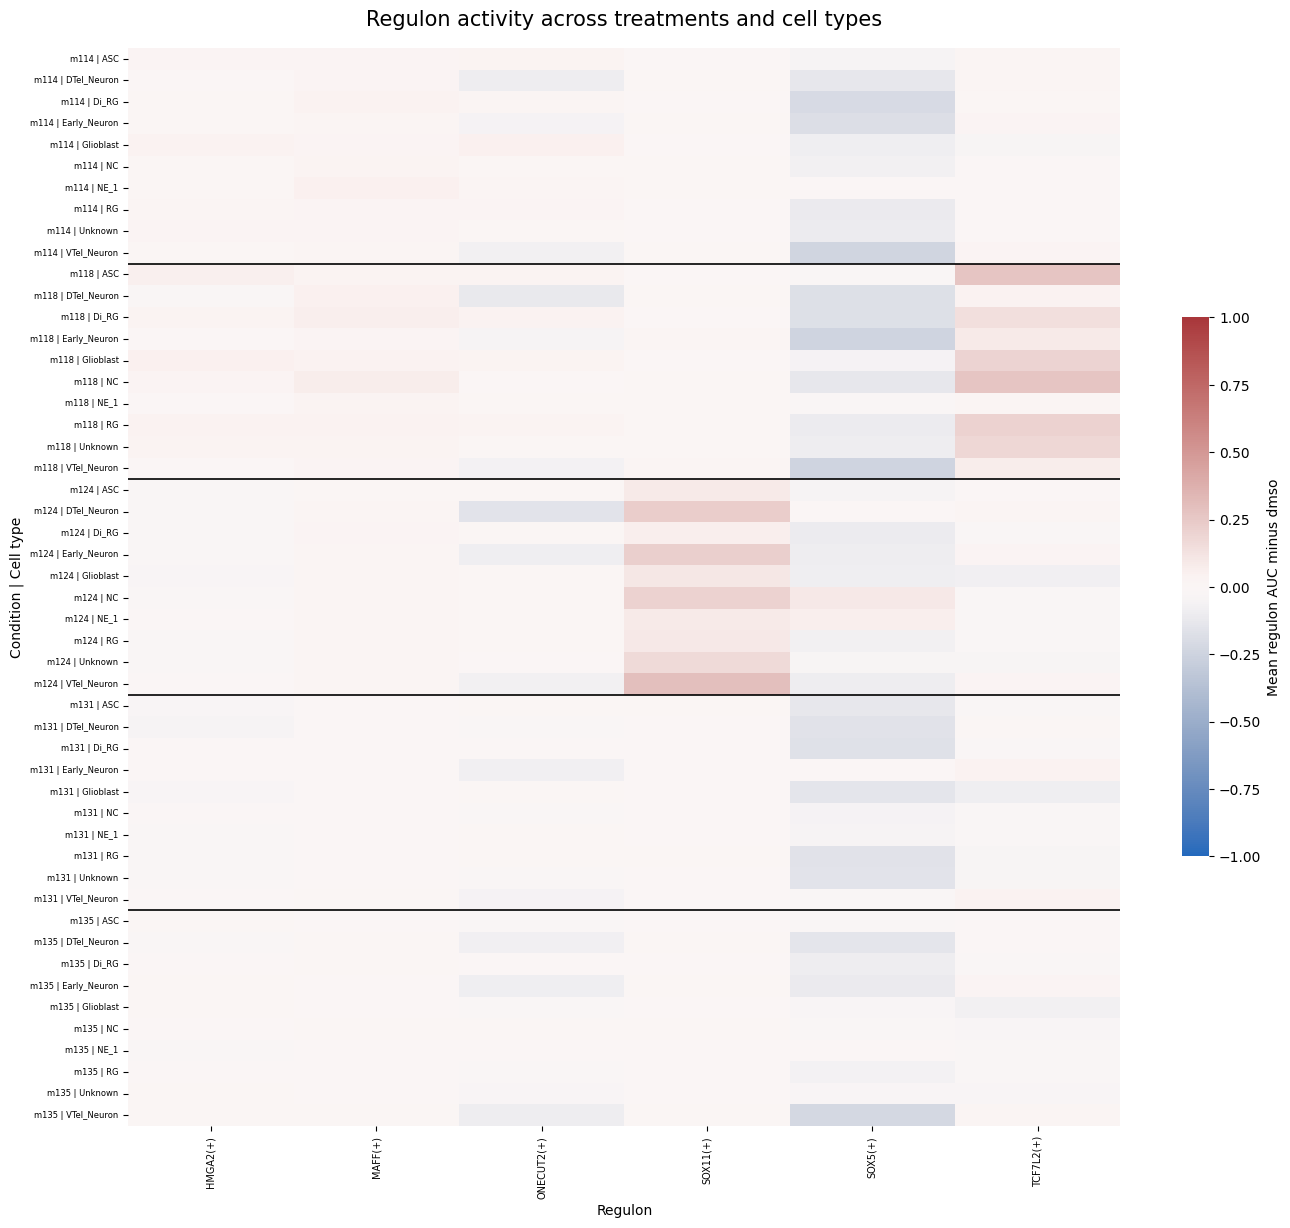

In [68]:
figure_dir = Path("/home/jiafzhou/GRN_org/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

n_rows, n_regulons = delta_mean_auc.shape

fig_width = max(16, n_regulons * 0.30)
fig_height = max(14, n_rows * 0.20)

fig, ax = plt.subplots(
    figsize=(fig_width, fig_height)
)

sns.heatmap(
    delta_mean_auc,
    ax=ax,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=True,
    yticklabels=[
        f"{condition} | {cell_type}"
        for condition, cell_type in delta_mean_auc.index
    ],
    cbar_kws={
        "label": "Mean regulon AUC minus dmso",
        "shrink": 0.5,
    },
)

# Add horizontal lines between conditions
condition_sizes = (
    delta_mean_auc
    .groupby(level="condition", sort=False)
    .size()
)

for boundary in condition_sizes.cumsum().iloc[:-1]:
    ax.axhline(
        boundary,
        color="black",
        linewidth=1.2,
    )

ax.set_title(
    "Regulon activity across treatments and cell types",
    fontsize=15,
    pad=16,
)

ax.set_xlabel("Regulon")
ax.set_ylabel("Condition | Cell type")

ax.tick_params(
    axis="x",
    labelrotation=90,
    labelsize=7,
)

ax.tick_params(
    axis="y",
    labelrotation=0,
    labelsize=6,
)

plt.savefig(
    figure_dir / "all_regulons_AUC_heatmap_minusdmso.pdf",
    bbox_inches="tight",
)

plt.savefig(
    figure_dir / "all_regulons_AUC_heatmap_minusdmso.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [20]:
regulon_sets = {}

mean_auc_tables

for drug in DRUGS_exist:

    auc = mean_auc_tables[drug]
    regulon_sets[drug] = set(auc.columns)

    print(
        drug,
        "| cell type:", auc.shape[0],
        "| regulons:", auc.shape[1],
    )

m124 | cell type: 11 | regulons: 60
m127 | cell type: 12 | regulons: 60
m121 | cell type: 12 | regulons: 60
m122 | cell type: 12 | regulons: 60
m126 | cell type: 12 | regulons: 60
m120 | cell type: 11 | regulons: 60
m138 | cell type: 12 | regulons: 60
m130 | cell type: 12 | regulons: 60
m114 | cell type: 12 | regulons: 60
m108 | cell type: 12 | regulons: 60
m119 | cell type: 12 | regulons: 60
m113 | cell type: 11 | regulons: 60
m133 | cell type: 11 | regulons: 60
m135 | cell type: 11 | regulons: 60
m112 | cell type: 12 | regulons: 60
m116 | cell type: 11 | regulons: 60
m123 | cell type: 12 | regulons: 60
m110 | cell type: 11 | regulons: 60
dmso | cell type: 12 | regulons: 60
m131 | cell type: 12 | regulons: 60
m115 | cell type: 12 | regulons: 60
m134 | cell type: 12 | regulons: 60
m111 | cell type: 12 | regulons: 60
m132 | cell type: 12 | regulons: 60
m117 | cell type: 12 | regulons: 60
m118 | cell type: 11 | regulons: 60
short-112 | cell type: 11 | regulons: 60
m109 | cell type: 12 | 

/home/jiafzhou/.conda/envs/pyscenic/lib/python3.10/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/jiafzhou/.conda/envs/pyscenic/lib/python3.10/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are sett

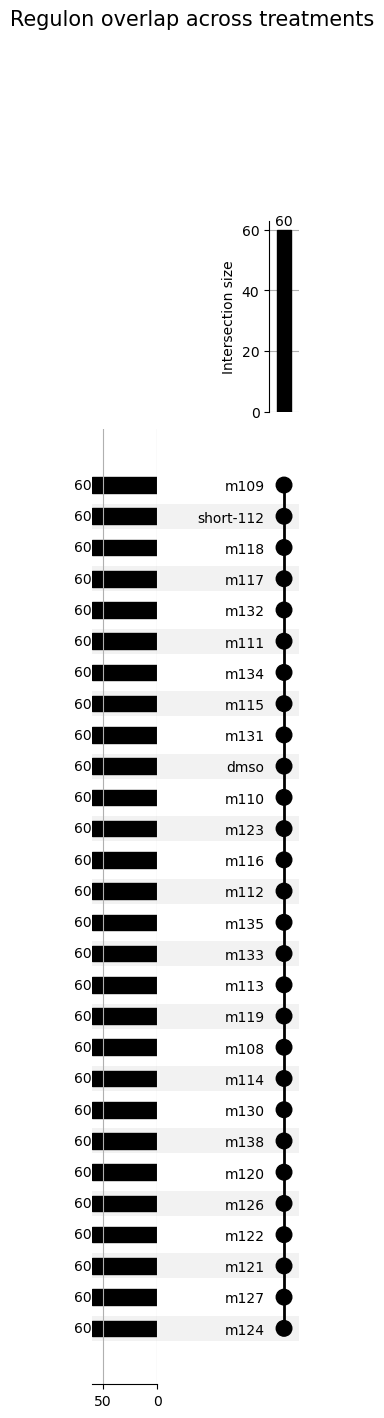

In [133]:
import matplotlib.pyplot as plt
from upsetplot import UpSet, from_contents

upset_data = from_contents(
    regulon_sets
)

fig = plt.figure(figsize=(14, 8))

upset = UpSet(
    upset_data,
    subset_size="count",
    show_counts=True,
    sort_by="cardinality",
    sort_categories_by="input",
    min_subset_size=1,
)

upset.plot(fig=fig)

plt.suptitle(
    "Regulon overlap across treatments",
    fontsize=15,
    y=1.02,
)

plt.savefig(
    "/home/jiafzhou/GRN_org/figures/regulon_upsetplot.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

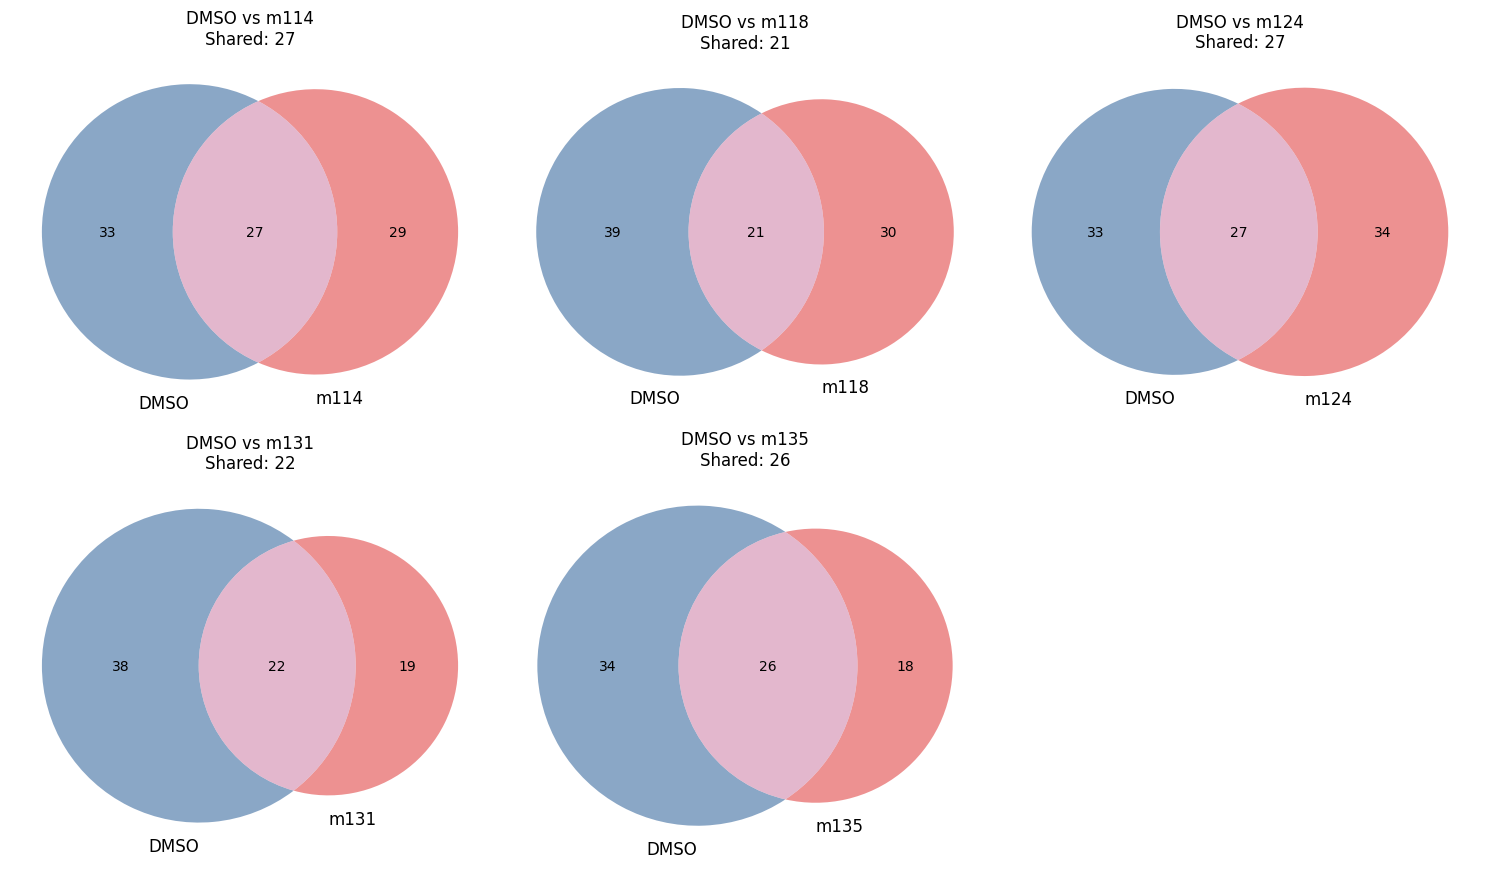

In [ ]:
from matplotlib_venn import venn2

drugs = [
    drug
    for drug in drug_list
    if drug != "dmso"
]

dmso_regulons = regulon_sets["dmso"]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9),
)

axes = axes.flatten()

for ax, drug in zip(axes, drugs):
    drug_regulons = regulon_sets[drug]

    shared = (
        dmso_regulons
        & drug_regulons
    )

    venn2(
        [
            dmso_regulons,
            drug_regulons,
        ],
        set_labels=[
            "DMSO",
            drug,
        ],
        set_colors=[
            "#4C78A8",
            "#E45756",
        ],
        alpha=0.65,
        ax=ax,
    )

    ax.set_title(
        f"DMSO vs {drug}\n"
        f"Shared: {len(shared)}"
    )

for ax in axes[len(drugs):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [80]:
mean_auc_combined.to_csv(
    "/home/jiafzhou/GRN_org/results/mean_auc_combined.csv"
)

# distance between dmso and drugs

use dmso regulons to calcualte auc_mtx

In [36]:
drug_all = pd.read_csv("/home/jiafzhou/GRN_org/config/included_drugs.txt", header=None)
DRUGS = drug_all[0].tolist()
base_result_dir = Path(f"/home/jiafzhou/GRN_org/results")
DRUGS_exist = []

for i in range(len(DRUGS)):
    auc_file = (
        base_result_dir
        / DRUGS[i]
        / "auc_mtx_pooled_allcells_ref.csv"
    )

    loom_file = (base_result_dir / DRUGS[i] / "input.loom")

    if not auc_file.is_file():
        print(f"Skip {DRUGS[i]}: AUC file missing")
        continue

    if not loom_file.is_file():
        print(f"Skip {DRUGS[i]}: Loom file missing")
        continue

    DRUGS_exist.append(DRUGS[i])

In [37]:
DRUGS_exist

['m124',
 'm127',
 'm121',
 'm122',
 'm126',
 'm128',
 'm120',
 'm138',
 'm130',
 'm114',
 'm108',
 'm125',
 'm119',
 'm113',
 'm133',
 'm135',
 'm112',
 'm129',
 'm116',
 'm123',
 'm110',
 'dmso',
 'm131',
 'm115',
 'm134',
 'm111',
 'm132',
 'm117',
 'm140',
 'short-117',
 'short-113',
 'm118',
 'short-112',
 'm109']

In [38]:

base_result_dir = Path(f"/home/jiafzhou/GRN_org/results")

mean_auc_dmsoref_tables = {}

for drug in DRUGS_exist:

    auc_ref = pd.read_csv(
        base_result_dir / drug / "auc_mtx_pooled_allcells_ref.csv",
        index_col=0,
    )

    auc_ref.index = auc_ref.index.astype(str)
    auc_ref.columns = auc_ref.columns.astype(str)

    with loompy.connect(
        str(base_result_dir / drug / "input.loom"),
        mode="r",
        validate=False,
    ) as ds:
        print(drug, list(ds.ca.keys()))

        cells = pd.Index(
            ds.ca["CellID"].astype(str)
        )

        # Change this key if your Loom uses a different name
        cell_types = pd.Series(
            ds.ca["CellType"].astype(str),
            index=cells,
            name="cell_type",
        )

    common_cells = auc_ref.index.intersection(cell_types.index)

    mean_auc_ref = (
        auc_ref.loc[common_cells]
        .groupby(cell_types.loc[common_cells])
        .mean()
    )

    mean_auc_ref.index.name = "cell_type"
    mean_auc_dmsoref_tables[drug] = mean_auc_ref

    print(
        drug,
        "cells:", len(common_cells),
        "mean AUC shape:", mean_auc_ref.shape,
    )

m124 ['CellID', 'CellType', 'Drug', 'Timepoint']
m124 cells: 4278 mean AUC shape: (10, 92)
m127 ['CellID', 'CellType', 'Drug', 'Timepoint']
m127 cells: 4577 mean AUC shape: (11, 92)
m121 ['CellID', 'CellType', 'Drug', 'Timepoint']
m121 cells: 4354 mean AUC shape: (10, 92)
m122 ['CellID', 'CellType', 'Drug', 'Timepoint']
m122 cells: 4291 mean AUC shape: (10, 92)
m126 ['CellID', 'CellType', 'Drug', 'Timepoint']
m126 cells: 4353 mean AUC shape: (10, 92)
m128 ['CellID', 'CellType', 'Drug', 'Timepoint']
m128 cells: 4386 mean AUC shape: (10, 92)
m120 ['CellID', 'CellType', 'Drug', 'Timepoint']
m120 cells: 4625 mean AUC shape: (9, 92)
m138 ['CellID', 'CellType', 'Drug', 'Timepoint']
m138 cells: 3420 mean AUC shape: (11, 92)
m130 ['CellID', 'CellType', 'Drug', 'Timepoint']
m130 cells: 4414 mean AUC shape: (10, 92)
m114 ['CellID', 'CellType', 'Drug', 'Timepoint']
m114 cells: 4031 mean AUC shape: (11, 92)
m108 ['CellID', 'CellType', 'Drug', 'Timepoint']
m108 cells: 4265 mean AUC shape: (11, 92)


In [39]:
mean_auc_dmsoref_tables["dmso"]

,ARX(+),ATF3(+),BARHL1(+),BBX(+),BCL11A(+),CREB3L2(+),DLX1(+),DLX2(+),DLX5(+),DLX6(+),...,TFAP2A(+),TP73(+),TPI1(+),TWIST1(+),UNCX(+),VSX1(+),VSX2(+),XBP1(+),YBX1(+),ZIC2(+)
cell_type,,,,,,,,,,,,,,,,,,,,,
ASC,0.078973,0.020460,0.145612,0.252175,0.077489,0.101606,0.079846,0.067533,0.048759,0.046815,...,0.022396,0.010227,0.035107,0.015211,0.031404,0.044651,0.050495,0.013117,0.036060,0.002684
DTel_Neuron,0.099448,0.020246,0.193698,0.271062,0.117785,0.070330,0.138074,0.109637,0.092783,0.111912,...,0.005790,0.000000,0.040344,0.006730,0.091606,0.049152,0.055708,0.018516,0.031700,0.000000
Di_RG,0.066538,0.025614,0.162428,0.287315,0.061711,0.112165,0.071651,0.059478,0.044406,0.045900,...,0.011829,0.004786,0.050444,0.017988,0.029421,0.047247,0.175932,0.019377,0.043829,0.004049
Early_Neuron,0.089964,0.017980,0.146551,0.226600,0.106257,0.063705,0.131347,0.119381,0.110452,0.093591,...,0.021987,0.010401,0.029678,0.007942,0.160770,0.079032,0.048465,0.010511,0.025781,0.000401
Glioblast,0.088753,0.018505,0.165681,0.296599,0.079203,0.111413,0.085133,0.071869,0.051334,0.051468,...,0.013411,0.002913,0.032512,0.011891,0.032766,0.061587,0.037584,0.010562,0.036497,0.002551
NC,0.054447,0.025620,0.152046,0.309802,0.068623,0.171581,0.063533,0.057892,0.050382,0.044843,...,0.045290,0.004197,0.055849,0.023568,0.033559,0.055418,0.047769,0.021323,0.050095,0.008344
NE_1,0.045709,0.037990,0.116710,0.263518,0.054003,0.084867,0.052561,0.051010,0.038220,0.036945,...,0.025272,0.003760,0.071529,0.013208,0.023688,0.036003,0.046919,0.042191,0.062468,0.005470
NE_2,0.088665,0.016744,0.169210,0.313020,0.093168,0.080057,0.099686,0.083725,0.073527,0.066093,...,0.016398,0.001945,0.031551,0.015754,0.046826,0.060946,0.041955,0.011413,0.037263,0.000000
NonTel_NE,0.074165,0.028254,0.258906,0.290229,0.069945,0.100805,0.064933,0.060476,0.049642,0.048486,...,0.022000,0.015565,0.055146,0.016978,0.025766,0.054851,0.070287,0.021096,0.052219,0.008604


In [124]:
mean_auc_dmsoref_tables

{'m124':                 ARX(+)   ATF3(+)  BARHL1(+)    BBX(+)  BCL11A(+)  CREB3L2(+)  \
 cell_type                                                                      
 ASC           0.080489  0.016108   0.124082  0.266454   0.076156    0.090808   
 DTel_Neuron   0.115351  0.016025   0.144633  0.215834   0.105340    0.054469   
 Di_RG         0.067106  0.028008   0.146377  0.262926   0.058365    0.107766   
 Early_Neuron  0.109550  0.019092   0.124223  0.185771   0.111413    0.048579   
 Glioblast     0.081025  0.017106   0.157575  0.311208   0.076165    0.116398   
 NC            0.099941  0.016331   0.140623  0.284156   0.090931    0.087499   
 NE_1          0.053946  0.031128   0.100369  0.245626   0.052854    0.091167   
 NonTel_NE     0.100248  0.021283   0.218225  0.382617   0.079332    0.095657   
 RG            0.071482  0.017833   0.110811  0.280995   0.069539    0.091012   
 VTel_Neuron   0.153418  0.013431   0.104091  0.192724   0.135282    0.050117   
 
                DL

In [65]:
mean_auc_dmsoref_tables.keys()

dict_keys(['m124', 'm127', 'm121', 'm122', 'm126', 'm128', 'm120', 'm138', 'm130', 'm114', 'm108', 'm125', 'm119', 'm113', 'm133', 'm135', 'm112', 'm129', 'm116', 'm123', 'm110', 'dmso', 'm131', 'm115', 'm134', 'm111', 'm132', 'm117', 'm140', 'short-117', 'short-113', 'm118', 'short-112', 'm109'])

In [41]:
common_regulons_ref = set.intersection(
    *(set(df.columns) for df in mean_auc_dmsoref_tables.values())
)
common_regulons_ref = sorted(common_regulons_ref)

In [42]:
common_celltypes_ref = set.intersection(
    *(set(df.index) for df in mean_auc_dmsoref_tables.values())
)

In [43]:
celltype_order = [
    cell_type
    for cell_type in mean_auc_dmsoref_tables["dmso"].index
    if cell_type in common_celltypes_ref
]

mean_auc_dmsoref_combined = pd.concat(
    {
        condition: mean_auc_dmsoref_tables[condition].loc[
            celltype_order,
            common_regulons_ref,
        ]
        for condition in DRUGS_exist
    },
    names=["condition", "cell_type"],
)

print(mean_auc_dmsoref_combined.shape)

(272, 92)


In [44]:
common_regulons_ref

['ARX(+)',
 'ATF3(+)',
 'BARHL1(+)',
 'BBX(+)',
 'BCL11A(+)',
 'CREB3L2(+)',
 'DLX1(+)',
 'DLX2(+)',
 'DLX5(+)',
 'DLX6(+)',
 'DMBX1(+)',
 'EBF1(+)',
 'EGR2(+)',
 'EGR3(+)',
 'EGR4(+)',
 'EMX1(+)',
 'EMX2(+)',
 'EOMES(+)',
 'ERG(+)',
 'ETS1(+)',
 'FLI1(+)',
 'FOSB(+)',
 'FOSL1(+)',
 'FOSL2(+)',
 'FOXD3(+)',
 'FOXO1(+)',
 'GATA3(+)',
 'GBX1(+)',
 'GSX2(+)',
 'HDAC2(+)',
 'HES5(+)',
 'HMGA1(+)',
 'HMGA2(+)',
 'HMGB2(+)',
 'HOXA2(+)',
 'IRF6(+)',
 'ISL1(+)',
 'JUNB(+)',
 'KLF13(+)',
 'LEF1(+)',
 'LHX2(+)',
 'LHX5(+)',
 'LHX6(+)',
 'LHX9(+)',
 'LMX1B(+)',
 'MAFF(+)',
 'MEIS1(+)',
 'MEOX2(+)',
 'MSX1(+)',
 'MSX2(+)',
 'MXI1(+)',
 'MYCN(+)',
 'NEUROD1(+)',
 'NEUROG1(+)',
 'NEUROG2(+)',
 'NFATC2(+)',
 'NR2F6(+)',
 'ONECUT1(+)',
 'ONECUT2(+)',
 'OTP(+)',
 'PAX6(+)',
 'PAX7(+)',
 'PBX3(+)',
 'POU2F2(+)',
 'POU3F1(+)',
 'POU3F3(+)',
 'POU3F4(+)',
 'POU4F1(+)',
 'PRDM6(+)',
 'RUNX2(+)',
 'RUNX3(+)',
 'RXRG(+)',
 'SIX6(+)',
 'SOX10(+)',
 'SOX11(+)',
 'SOX2(+)',
 'SOX21(+)',
 'SOX4(+)',
 'STAT4(+)'

In [45]:
mean_auc_dmsoref_combined

ARX(+)   ATF3(+)  BARHL1(+)    BBX(+)  BCL11A(+)  \
condition cell_type                                                          
m124      ASC           0.080489  0.016108   0.124082  0.266454   0.076156   
          Di_RG         0.067106  0.028008   0.146377  0.262926   0.058365   
          Early_Neuron  0.109550  0.019092   0.124223  0.185771   0.111413   
          Glioblast     0.081025  0.017106   0.157575  0.311208   0.076165   
          NC            0.099941  0.016331   0.140623  0.284156   0.090931   
...                          ...       ...        ...       ...        ...   
m109      Glioblast     0.073314  0.022686   0.217053  0.317898   0.067806   
          NC            0.049965  0.026760   0.147101  0.302803   0.063151   
          NE_1          0.037732  0.037914   0.112507  0.209696   0.044474   
          RG            0.057819  0.021934   0.153270  0.314632   0.060419   
          VTel_Neuron   0.113612  0.019425   0.085206  0.204595   0.112701   

                        CREB3L2(+)   DLX1(+)   DLX2(+)   DLX5(+)   DLX6(+)  \
condition cell_type                                                          
m124      ASC             0.090808  0.099605  0.076901  0.058342  0.052371   
          Di_RG           0.107766  0.073464  0.055736  0.046515  0.046815   
          Early_Neuron    0.048579  0.149260  0.127433  0.126176  0.105054   
          Glioblast       0.116398  0.086401  0.067796  0.054725  0.051940   
          NC              0.087499  0.135395  0.105282  0.093839  0.083094   
...                            ...       ...       ...       ...       ...   
m109      Glioblast       0.119453  0.064302  0.053633  0.045526  0.034516   
          NC              0.189583  0.053468  0.047128  0.043069  0.034249   
          NE_1            0.096033  0.038404  0.040186  0.037412  0.029558   
          RG              0.111197  0.066402  0.060124  0.049247  0.043622   
          VTel_Neuron     0.060366  0.175324  0.162604  0.165190  0.140785   

                        ...  TFAP2A(+)   TP73(+)   TPI1(+)  TWIST1(+)  \
condition cell_type     ...                                             
m124      ASC           ...   0.011040  0.013052  0.028908   0.015589   
          Di_RG         ...   0.014539  0.005748  0.055185   0.017025   
          Early_Neuron  ...   0.021369  0.022083  0.030652   0.010415   
          Glioblast     ...   0.018334  0.007648  0.030293   0.017330   
          NC            ...   0.012019  0.007346  0.039693   0.014781   
...                     ...        ...       ...       ...        ...   
m109      Glioblast     ...   0.018751  0.009505  0.016132   0.023140   
          NC            ...   0.052672  0.010411  0.024505   0.057494   
          NE_1          ...   0.025869  0.010802  0.050239   0.020165   
          RG            ...   0.012955  0.012985  0.022176   0.019594   
          VTel_Neuron   ...   0.013518  0.029467  0.027183   0.022925   

                         UNCX(+)   VSX1(+)   VSX2(+)   XBP1(+)   YBX1(+)  \
condition cell_type                                                        
m124      ASC           0.028880  0.040947  0.038596  0.011831  0.033782   
          Di_RG         0.023677  0.039854  0.163585  0.022381  0.046202   
          Early_Neuron  0.122872  0.064416  0.037076  0.012010  0.024546   
          Glioblast     0.037125  0.055088  0.034689  0.012196  0.035347   
          NC            0.047754  0.053478  0.047489  0.014040  0.037286   
...                          ...       ...       ...       ...       ...   
m109      Glioblast     0.020332  0.051701  0.055356  0.012417  0.028243   
          NC            0.033532  0.051028  0.045402  0.018918  0.030493   
          NE_1          0.020719  0.031001  0.044191  0.038045  0.055920   
          RG            0.017344  0.034976  0.048291  0.015485  0.035247   
          VTel_Neuron   0.056457  0.055132  0.085531  0.020302  0.030107   

                         ZIC2(+)  
condition cell_type   

In [46]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [47]:
condition_profiles = (
    mean_auc_dmsoref_combined
    .unstack("cell_type")
)

condition_profiles = (
    condition_profiles
    .replace([np.inf, -np.inf], np.nan)
    .dropna(axis=1, how="any")
)

condition_pca = PCA(n_components=2)

condition_coordinates = (
    condition_pca.fit_transform(
        condition_profiles
    )
)

condition_pca_table = pd.DataFrame(
    condition_coordinates,
    index=condition_profiles.index,
    columns=["PC1", "PC2"],
)

condition_pca_table

,PC1,PC2
condition,,
m124,-0.083453,0.020540
m127,0.187388,-0.012676
m121,0.089501,0.070489
m122,0.151370,-0.028423
m126,0.158876,0.019036
m128,0.056173,0.014177
m120,0.040481,-0.013252
m138,-0.135324,-0.145047
m130,0.085948,0.094067


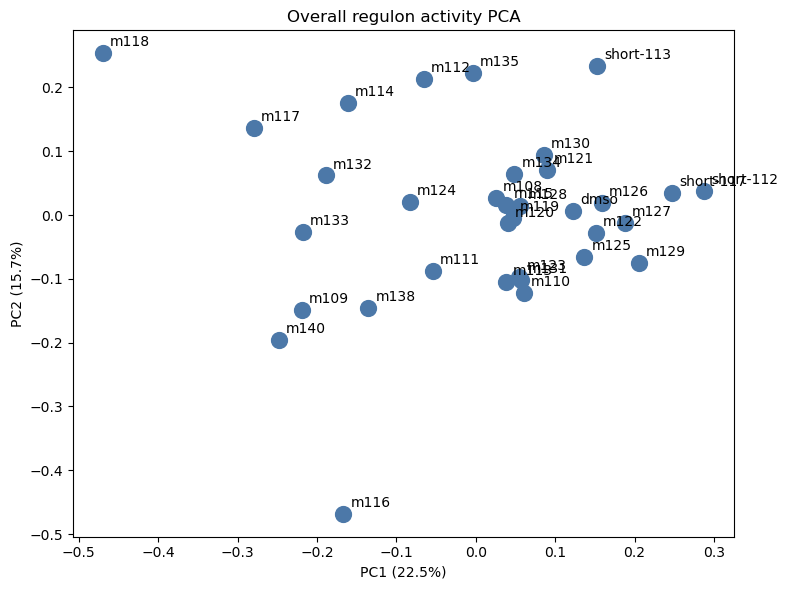

In [48]:
from matplotlib import pyplot as plt
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    condition_pca_table["PC1"],
    condition_pca_table["PC2"],
    s=130,
    color="#4C78A8",
)

for condition, row in condition_pca_table.iterrows():
    ax.annotate(
        condition,
        (row["PC1"], row["PC2"]),
        xytext=(5, 5),
        textcoords="offset points",
    )

ax.set_xlabel(
    f"PC1 ({condition_pca.explained_variance_ratio_[0] * 100:.1f}%)"
)

ax.set_ylabel(
    f"PC2 ({condition_pca.explained_variance_ratio_[1] * 100:.1f}%)"
)

ax.set_title(
    "Overall regulon activity PCA"
)

plt.tight_layout()
plt.show()

#all drugs pca
remove unkown cell type

import list of inhibitor histone mark, color dots by histoneTarget, histoneFunction, 

In [49]:
meta = pd.read_csv("/home/jiafzhou/GRN_org/List_inhibitor_histone_mark_target_name.csv")
meta

,drug,histoneTarget,histoneColor,histoneFunction,targetComplex,expectedGEX,molecularTarget,drugName,histoneComplex
0,m131,ACETYLATION,#4b9700,ACTIVE,ERASER,+,HDAC3,RGFP966,ACETYLATION_ERASER
1,m133,ACETYLATION,#4b9700,ACTIVE,READER,-,BRD2/3/4_BRDT,JQ1,ACETYLATION_READER
2,m139,ACETYLATION,#4b9700,ACTIVE,READER,-,BRD2,ARV771,ACETYLATION_READER
3,dmso,CONTROL,#050505,CTRL,CONTROL,CONTROL,CONTROL,DMSO,CONTROL_CONTROL
4,m138,DNAm,#872287,REPRESSIVE,WRITER,+,DNMT1,GSK-3484862,DNAm_WRITER
5,m116,H3K27AC,#009697,ACTIVE,WRITER,-,CBP/p300,A485,H3K27AC_WRITER
6,m137,H3K27ME3,#027BB8,REPRESSIVE,ERASER,-,KDM6A/B_UTX,GSKJ4,H3K27ME3_ERASER
7,m122,H3K27ME3,#027BB8,REPRESSIVE,READER,+,CBX4/7,UNC3866,H3K27ME3_READER
8,m123,H3K27ME3,#027BB8,REPRESSIVE,READER,+,CBX8,SW2_110A,H3K27ME3_READER
9,m135,H3K27ME3,#027BB8,REPRESSIVE,READER,+,EED,A395,H3K27ME3_READER


In [50]:
pca_table = (
    condition_pca_table
    .rename_axis("drug")
    .reset_index()
)

combined_table = meta.merge(
    pca_table,
    on="drug",
    how="left",
)

combined_table

,drug,histoneTarget,histoneColor,histoneFunction,targetComplex,expectedGEX,molecularTarget,drugName,histoneComplex,PC1,PC2
0,m131,ACETYLATION,#4b9700,ACTIVE,ERASER,+,HDAC3,RGFP966,ACETYLATION_ERASER,0.056709,-0.102364
1,m133,ACETYLATION,#4b9700,ACTIVE,READER,-,BRD2/3/4_BRDT,JQ1,ACETYLATION_READER,-0.217912,-0.027024
2,m139,ACETYLATION,#4b9700,ACTIVE,READER,-,BRD2,ARV771,ACETYLATION_READER,NaN,NaN
3,dmso,CONTROL,#050505,CTRL,CONTROL,CONTROL,CONTROL,DMSO,CONTROL_CONTROL,0.122210,0.006758
4,m138,DNAm,#872287,REPRESSIVE,WRITER,+,DNMT1,GSK-3484862,DNAm_WRITER,-0.135324,-0.145047
5,m116,H3K27AC,#009697,ACTIVE,WRITER,-,CBP/p300,A485,H3K27AC_WRITER,-0.166721,-0.468141
6,m137,H3K27ME3,#027BB8,REPRESSIVE,ERASER,-,KDM6A/B_UTX,GSKJ4,H3K27ME3_ERASER,NaN,NaN
7,m122,H3K27ME3,#027BB8,REPRESSIVE,READER,+,CBX4/7,UNC3866,H3K27ME3_READER,0.151370,-0.028423
8,m123,H3K27ME3,#027BB8,REPRESSIVE,READER,+,CBX8,SW2_110A,H3K27ME3_READER,0.054920,-0.097493
9,m135,H3K27ME3,#027BB8,REPRESSIVE,READER,+,EED,A395,H3K27ME3_READER,-0.004006,0.223337


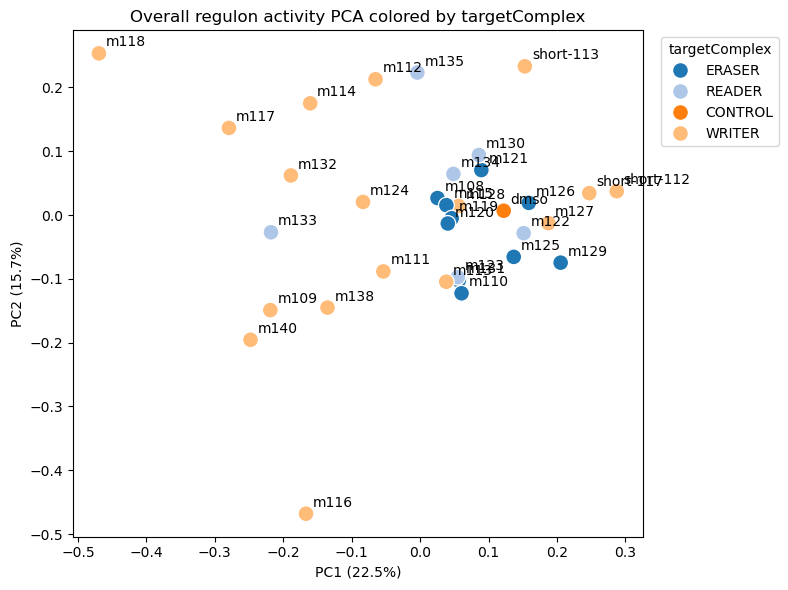

In [51]:
import seaborn as sns

color_by = "targetComplex" 

plot_data = combined_table.dropna(
    subset=["PC1", "PC2", color_by]
)

fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=plot_data,
    x="PC1",
    y="PC2",
    hue=color_by,
    palette="tab20",
    s=130,
    ax=ax,
)

for _, row in plot_data.iterrows():
    ax.annotate(
        row["drug"],
        (row["PC1"], row["PC2"]),
        xytext=(5, 5),
        textcoords="offset points",
    )

ax.set_xlabel(
    f"PC1 ({condition_pca.explained_variance_ratio_[0] * 100:.1f}%)"
)
ax.set_ylabel(
    f"PC2 ({condition_pca.explained_variance_ratio_[1] * 100:.1f}%)"
)
ax.set_title(f"Overall regulon activity PCA colored by {color_by}")

ax.legend(
    title=color_by,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()

plt.savefig(
    "/home/jiafzhou/GRN_org/figures/all_drugs_pca.pdf",
    bbox_inches="tight",
)

plt.show()

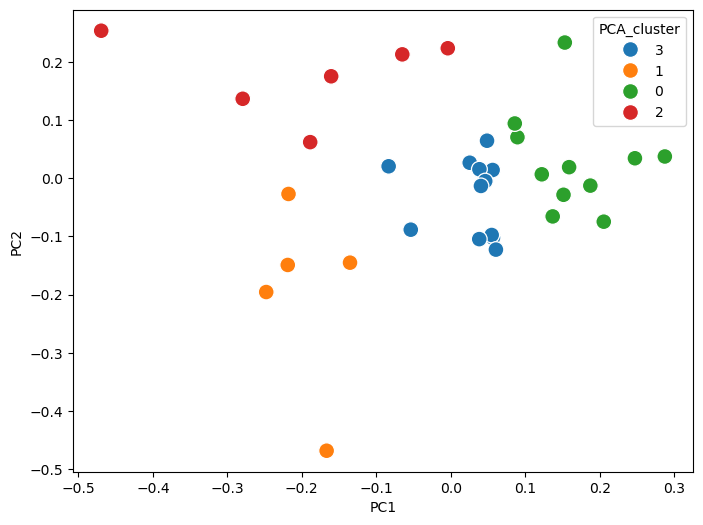

In [52]:
from sklearn.cluster import KMeans

plot_data = combined_table.dropna(
    subset=["PC1", "PC2"]
).copy()

n_clusters = 4

kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=42,
    n_init=50,
)

plot_data["PCA_cluster"] = (
    kmeans
    .fit_predict(plot_data[["PC1", "PC2"]])
    .astype(str)
)

color_by = "PCA_cluster"

fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=plot_data,
    x="PC1",
    y="PC2",
    hue=color_by,
    palette="tab10",
    s=130,
    ax=ax,
)

plt.savefig(
    "/home/jiafzhou/GRN_org/figures/all_drugs_pca_bycluster.pdf",
    bbox_inches="tight",
)

plt.show()

In [53]:
import numpy as np

dmso_point = (
    combined_table
    .loc[combined_table["drug"] == "dmso", ["PC1", "PC2"]]
    .iloc[0]
)

combined_table["distance_to_dmso"] = np.sqrt(
    (combined_table["PC1"] - dmso_point["PC1"]) ** 2
    + (combined_table["PC2"] - dmso_point["PC2"]) ** 2
)

In [29]:
combined_table

,drug,histoneTarget,histoneColor,histoneFunction,targetComplex,expectedGEX,molecularTarget,drugName,histoneComplex,PC1,PC2,distance_to_dmso
0,m131,ACETYLATION,#4b9700,ACTIVE,ERASER,+,HDAC3,RGFP966,ACETYLATION_ERASER,0.056709,-0.102364,0.127271
1,m133,ACETYLATION,#4b9700,ACTIVE,READER,-,BRD2/3/4_BRDT,JQ1,ACETYLATION_READER,-0.217912,-0.027024,0.341796
2,m139,ACETYLATION,#4b9700,ACTIVE,READER,-,BRD2,ARV771,ACETYLATION_READER,NaN,NaN,NaN
3,dmso,CONTROL,#050505,CTRL,CONTROL,CONTROL,CONTROL,DMSO,CONTROL_CONTROL,0.122210,0.006758,0.000000
4,m138,DNAm,#872287,REPRESSIVE,WRITER,+,DNMT1,GSK-3484862,DNAm_WRITER,-0.135324,-0.145047,0.298946
5,m116,H3K27AC,#009697,ACTIVE,WRITER,-,CBP/p300,A485,H3K27AC_WRITER,-0.166721,-0.468141,0.555887
6,m137,H3K27ME3,#027BB8,REPRESSIVE,ERASER,-,KDM6A/B_UTX,GSKJ4,H3K27ME3_ERASER,NaN,NaN,NaN
7,m122,H3K27ME3,#027BB8,REPRESSIVE,READER,+,CBX4/7,UNC3866,H3K27ME3_READER,0.151370,-0.028423,0.045695
8,m123,H3K27ME3,#027BB8,REPRESSIVE,READER,+,CBX8,SW2_110A,H3K27ME3_READER,0.054920,-0.097493,0.124082
9,m135,H3K27ME3,#027BB8,REPRESSIVE,READER,+,EED,A395,H3K27ME3_READER,-0.004006,0.223337,0.250673


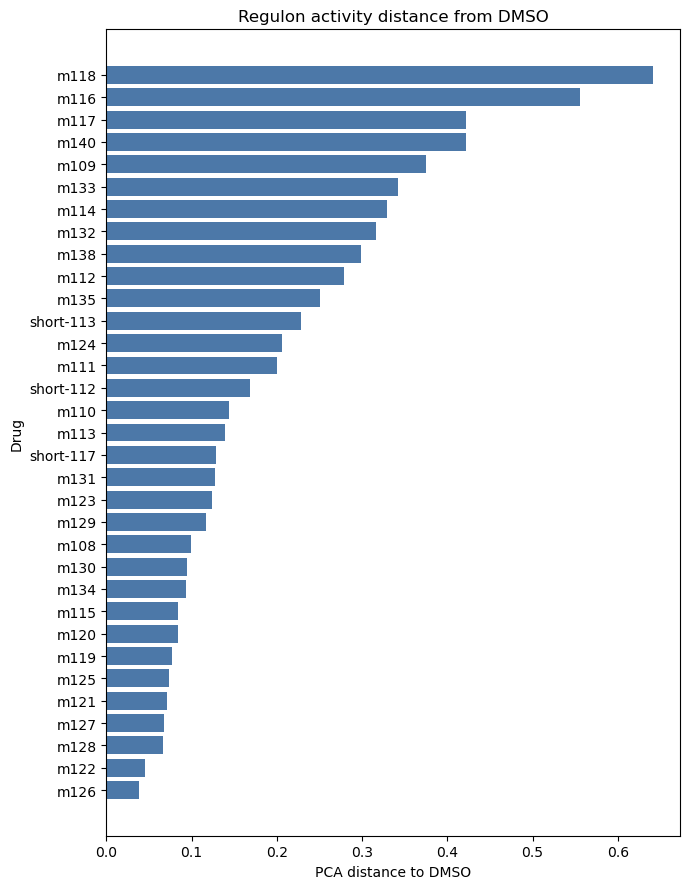

In [54]:
distance_plot = (
    combined_table
    .query("drug != 'dmso'")
    .dropna(subset=["distance_to_dmso"])
    .sort_values("distance_to_dmso")
)

plt.figure(figsize=(7, 9))

plt.barh(
    distance_plot["drug"],
    distance_plot["distance_to_dmso"],
    color="#4C78A8",
)

plt.xlabel("PCA distance to DMSO")
plt.ylabel("Drug")
plt.title("Regulon activity distance from DMSO")
plt.tight_layout()
plt.savefig(
    "/home/jiafzhou/GRN_org/figures/all_drugs_pca_distance.pdf",
    bbox_inches="tight"
)
plt.show()

# cosine similarity

In [ ]:
mean_auc_dmsoref_combined.index.get_level_values("condition").unique().tolist()

In [118]:
mean_auc_dmsoref_combined

ARX(+)   ATF3(+)  BARHL1(+)    BBX(+)  BCL11A(+)  \
condition cell_type                                                          
m124      ASC           0.080489  0.016108   0.124082  0.266454   0.076156   
          Di_RG         0.067106  0.028008   0.146377  0.262926   0.058365   
          Early_Neuron  0.109550  0.019092   0.124223  0.185771   0.111413   
          Glioblast     0.081025  0.017106   0.157575  0.311208   0.076165   
          NC            0.099941  0.016331   0.140623  0.284156   0.090931   
...                          ...       ...        ...       ...        ...   
m109      Glioblast     0.073314  0.022686   0.217053  0.317898   0.067806   
          NC            0.049965  0.026760   0.147101  0.302803   0.063151   
          NE_1          0.037732  0.037914   0.112507  0.209696   0.044474   
          RG            0.057819  0.021934   0.153270  0.314632   0.060419   
          VTel_Neuron   0.113612  0.019425   0.085206  0.204595   0.112701   

                        CREB3L2(+)   DLX1(+)   DLX2(+)   DLX5(+)   DLX6(+)  \
condition cell_type                                                          
m124      ASC             0.090808  0.099605  0.076901  0.058342  0.052371   
          Di_RG           0.107766  0.073464  0.055736  0.046515  0.046815   
          Early_Neuron    0.048579  0.149260  0.127433  0.126176  0.105054   
          Glioblast       0.116398  0.086401  0.067796  0.054725  0.051940   
          NC              0.087499  0.135395  0.105282  0.093839  0.083094   
...                            ...       ...       ...       ...       ...   
m109      Glioblast       0.119453  0.064302  0.053633  0.045526  0.034516   
          NC              0.189583  0.053468  0.047128  0.043069  0.034249   
          NE_1            0.096033  0.038404  0.040186  0.037412  0.029558   
          RG              0.111197  0.066402  0.060124  0.049247  0.043622   
          VTel_Neuron     0.060366  0.175324  0.162604  0.165190  0.140785   

                        ...  TFAP2A(+)   TP73(+)   TPI1(+)  TWIST1(+)  \
condition cell_type     ...                                             
m124      ASC           ...   0.011040  0.013052  0.028908   0.015589   
          Di_RG         ...   0.014539  0.005748  0.055185   0.017025   
          Early_Neuron  ...   0.021369  0.022083  0.030652   0.010415   
          Glioblast     ...   0.018334  0.007648  0.030293   0.017330   
          NC            ...   0.012019  0.007346  0.039693   0.014781   
...                     ...        ...       ...       ...        ...   
m109      Glioblast     ...   0.018751  0.009505  0.016132   0.023140   
          NC            ...   0.052672  0.010411  0.024505   0.057494   
          NE_1          ...   0.025869  0.010802  0.050239   0.020165   
          RG            ...   0.012955  0.012985  0.022176   0.019594   
          VTel_Neuron   ...   0.013518  0.029467  0.027183   0.022925   

                         UNCX(+)   VSX1(+)   VSX2(+)   XBP1(+)   YBX1(+)  \
condition cell_type                                                        
m124      ASC           0.028880  0.040947  0.038596  0.011831  0.033782   
          Di_RG         0.023677  0.039854  0.163585  0.022381  0.046202   
          Early_Neuron  0.122872  0.064416  0.037076  0.012010  0.024546   
          Glioblast     0.037125  0.055088  0.034689  0.012196  0.035347   
          NC            0.047754  0.053478  0.047489  0.014040  0.037286   
...                          ...       ...       ...       ...       ...   
m109      Glioblast     0.020332  0.051701  0.055356  0.012417  0.028243   
          NC            0.033532  0.051028  0.045402  0.018918  0.030493   
          NE_1          0.020719  0.031001  0.044191  0.038045  0.055920   
          RG            0.017344  0.034976  0.048291  0.015485  0.035247   
          VTel_Neuron   0.056457  0.055132  0.085531  0.020302  0.030107   

                         ZIC2(+)  
condition cell_type   

 AUC + cosine similarity to group drugs having similar direction 

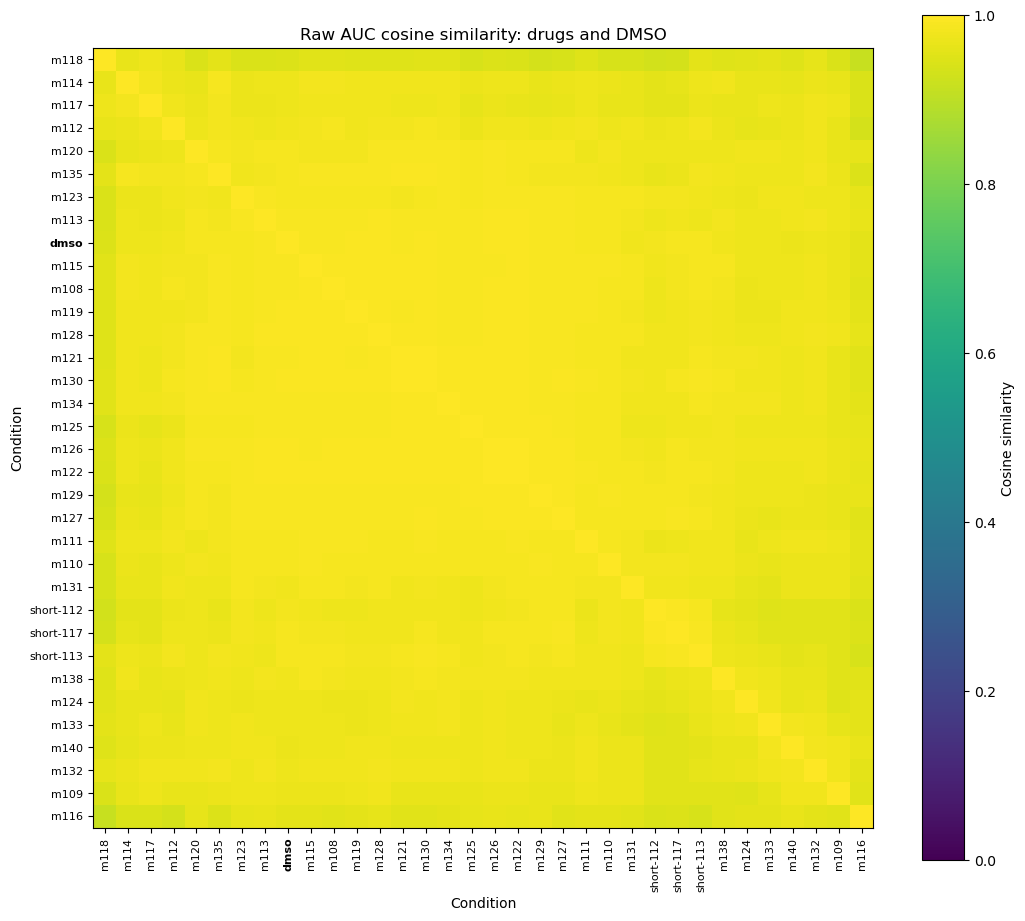

In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, leaves_list

DMSO_LABEL = "dmso" 

df_raw = mean_auc_dmsoref_combined.copy().astype(float)


conditions = df_raw.index.get_level_values("condition").unique()


# Rows: DMSO + drugs
# Columns: (TF, cell_type)
X_raw_all = df_raw.unstack("cell_type")

X_raw = (
    X_raw_all
    .replace([np.inf, -np.inf], np.nan)
    .dropna(axis=1, how="any")
)

norms = np.linalg.norm(X_raw.to_numpy(), axis=1)

# ---------- 2. Cosine similarity ----------
D_raw = pdist(X_raw.to_numpy(), metric="cosine")

D_raw = np.clip(D_raw, 0.0, 2.0)

sim_raw = pd.DataFrame(
    1.0 - squareform(D_raw),
    index=X_raw.index,
    columns=X_raw.index
)

Z_raw = linkage(
    D_raw,
    method="average",
    optimal_ordering=True
)

order_raw = leaves_list(Z_raw)
sim_raw_ordered = sim_raw.iloc[order_raw, order_raw]

# ---------- 4. Heatmap ----------
labels = sim_raw_ordered.index.astype(str).tolist()
n = len(labels)

fig, ax = plt.subplots(
    figsize=(max(8, 0.32 * n), max(7, 0.32 * n))
)

im = ax.imshow(
    sim_raw_ordered.to_numpy(),
    vmin=0,
    vmax=1,
    interpolation="nearest",
    aspect="equal"
)

ax.set_xticks(np.arange(n))
ax.set_yticks(np.arange(n))
ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set_yticklabels(labels, fontsize=8)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    if tick.get_text() == str(DMSO_LABEL):
        tick.set_fontweight("bold")

ax.set_title("Raw AUC cosine similarity: drugs and DMSO")
ax.set_xlabel("Condition")
ax.set_ylabel("Condition")

fig.colorbar(im, ax=ax, label="Cosine similarity", shrink=0.8)

fig.tight_layout()
plt.show()

In [119]:
# 各 condition 相对于 DMSO 的变化
delta_from_dmso = X_raw.sub(
    X_raw.loc[DMSO_LABEL],
    axis="columns"
)

# 同时汇总模式相似性和数值偏离幅度
drug_vs_dmso = pd.DataFrame(
    {
        "cosine_to_DMSO": sim_raw[DMSO_LABEL],
        "RMS_delta_AUC": np.sqrt(
            delta_from_dmso.pow(2).mean(axis=1)
        )
    }
)

drug_vs_dmso = (
    drug_vs_dmso
    .drop(index=DMSO_LABEL)
    .sort_values("cosine_to_DMSO", ascending=False)
)

print(drug_vs_dmso.round(6))

           cosine_to_DMSO  RMS_delta_AUC
condition                               
m130             0.993159       0.009912
m128             0.992911       0.010203
m122             0.992559       0.010527
m126             0.992400       0.011719
m119             0.992275       0.010501
m121             0.992054       0.010761
m127             0.991961       0.010702
m129             0.991519       0.011219
m134             0.991278       0.011295
m125             0.991202       0.011205
m115             0.991182       0.011289
m108             0.990704       0.011602
m113             0.988638       0.012712
m120             0.987809       0.013208
m123             0.987434       0.013376
m135             0.987224       0.014932
m110             0.987097       0.014219
m111             0.985255       0.015253
short-113        0.984808       0.015334
short-117        0.984503       0.014844
short-112        0.984082       0.015263
m131             0.979734       0.016971
m138            

In [121]:
# 沿用前面的变量：
# X_raw: condition × (TF, cell_type)，包含 DMSO
# DMSO_LABEL: 实际的 DMSO 名称

# 相对于 DMSO 的变化
delta = X_raw.sub(
    X_raw.loc[DMSO_LABEL],
    axis="columns"
)

# 在每个 cell type 内，对 TF 的 ΔAUC 计算 RMS
rms_by_celltype = (
    delta.pow(2)
    .T.groupby(level="cell_type").mean()
    .T.pow(0.5)
    .drop(index=DMSO_LABEL)
)

# Rows: drugs
# Columns: cell types
rms_by_celltype

cell_type,ASC,Di_RG,Early_Neuron,Glioblast,NC,NE_1,RG,VTel_Neuron
condition,,,,,,,,
m124,0.017021,0.010506,0.023348,0.012618,0.037712,0.016523,0.012740,0.014539
m127,0.015609,0.009920,0.007152,0.013414,0.012044,0.008122,0.008989,0.007169
m121,0.017233,0.007762,0.007629,0.010576,0.015167,0.008738,0.007106,0.006497
m122,0.018310,0.008098,0.005676,0.008599,0.015021,0.006523,0.008433,0.006339
m126,0.020309,0.009924,0.007346,0.008948,0.013959,0.009001,0.010812,0.007812
m128,0.015805,0.008884,0.007364,0.011024,0.011932,0.008099,0.007688,0.007830
m120,0.015723,0.011844,0.018374,0.010099,0.017188,0.009315,0.010004,0.009286
m138,0.021170,0.021824,0.019228,0.017566,0.032719,0.016772,0.014763,0.016646
m130,0.020309,0.005956,0.006964,0.008705,0.008866,0.006678,0.006431,0.007015


In [123]:


pearson_sim = X_raw.T.corr(method="pearson")

comparison = pd.DataFrame({
    "cosine_to_DMSO": sim_raw[DMSO_LABEL],
    "pearson_to_DMSO": pearson_sim[DMSO_LABEL]
}).drop(index=DMSO_LABEL)

comparison.sort_values("pearson_to_DMSO", ascending=False)

,cosine_to_DMSO,pearson_to_DMSO
condition,,
m130,0.993159,0.984226
m128,0.992911,0.983970
m126,0.992400,0.983276
m119,0.992275,0.983028
m122,0.992559,0.983022
m121,0.992054,0.981401
m127,0.991961,0.981216
m129,0.991519,0.980458
m125,0.991202,0.980262


Run SCENIC per condition

• Run SCENIC jointly on all cells (consistent regulon definitions)

• Then compare AUCell scores between conditions per cell type

• Avoids regulon definition differences confounding comparison

Score each perturbation

For each inhibitor vs control comparison, extract:

Number of differential regulons (how many regulons pass the threshold and in which direction)

Effect size of top TF changes (log2FC of mean AUCell score per condition)

Consistency across cell types (Check FDR per regulon per cell types and the fold change direction)

Known epi-target TFs affected (like Hox in EZH2i, myc in HDACi and BRDi, GATA in LSD1i…)

Novel/unexpected TF activation (should be low in control and consistent across cell types)

Cell state shift magnitude (in PCA space ordinal regression??)

We could build a score where we weight these changes differently to prioritize for multiome
‌
Prioritize perturbations for multiome

Select inhibitors that show:

• Strong, consistent regulon shifts across cell types

• Activation of TFs linked to chromatin (pioneer factors, PRC2 targets, etc.)

• Discordance between TF expression and regulon activity would suggests chromatin-level regulation not captured by RNA alone highest priority for multiome! but unlikely ;)